# Laser keyhole depth in additive manufacturing

This notebook executes the real LangGraph workflow with the supplied case prompt and overrides. All stage cards and final plots are retained below. New execution results are recorded separately from historical evidence.

Set `OPENAI_API_KEY` and `PARATERA_API_KEY` in the kernel environment. See the repository README for endpoint configuration. Credentials never belong in notebook cells.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs' / 'cases').is_dir() and (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))

from ai_buckingham import build_agent_graph
from ai_buckingham.cli import load_case, run_analysis
from ai_buckingham.artifacts import new_run_id, read_json
from IPython.display import display, Markdown
import pandas as pd

In [2]:
CASE_ID = 'laser_keyhole'
case = load_case(CASE_ID)
RUN_DIR = ROOT / 'results' / 'cases' / CASE_ID / new_run_id()
display(Markdown(case['prompt']))
frame = pd.read_csv(ROOT / case['dataset'])
print(f'Original observations: {len(frame)}; columns: {list(frame.columns)}')
display(frame.head())
print('Declared manual overrides:')
display(case['manual_hyperparams'])

Perform dimensional analysis for laser-melted liquid metal to derive the dimensionless form of the keyhole depth (denoted as e*). 
This analysis uses ONLY the following 7 physical quantities as input parameters: 
the material density (ρ), the temperature difference between melting temperature and ambient temperature (Tl − T0), the laser beam radius (r0), and the thermal diffusivity (α), the effective laser power (ηP), the heat capacity (cp), the laser scan speed (Vs).

Original observations: 90; columns: ['rho', 'Tl-T0', 'r0', 'alpha', 'etaP', 'cp', 'Vs', 'case', 'source', 'Tv-T0', 'Lv', 'Lm', 'e', 'Ke', 'e*']


,rho,Tl-T0,r0,alpha,etaP,cp,Vs,case,source,Tv-T0,Lv,Lm,e,Ke,e*
0,3920,1630,0.000048,0.00001,45.62,830,0.4,keyhole,Mat1,3267,9255000,286000,0.000033,4.127513,0.694905
1,3920,1630,0.000048,0.00001,64.64,830,0.4,keyhole,Mat1,3267,9255000,286000,0.000085,5.848969,1.796282
2,3920,1630,0.000048,0.00001,84.68,830,0.4,keyhole,Mat1,3267,9255000,286000,0.000130,7.662082,2.745032
3,3920,1630,0.000048,0.00001,124.86,830,0.4,keyhole,Mat1,3267,9255000,286000,0.000227,11.296977,4.774021
4,3920,1630,0.000048,0.00001,142.17,830,0.4,keyhole,Mat1,3267,9255000,286000,0.000259,12.863577,5.459368


Declared manual overrides:


{'workflow_template': 'auto_mechanism_adaptive',
 'similarity_type': 'auto',
 'max_rational_denominator': 5,
 'mi_param_used': 4,
 'mi_method_used': 'kraskov',
 'cma_init_position': 0.1,
 'cma_init_stepsize': 0.5}

In [3]:
# Build the same nine-node graph used by the CLI and Streamlit.
# This step does not initialize models or make API calls.
agent_graph = build_agent_graph()
print(agent_graph.get_graph().draw_mermaid())

D:\zFILES\MiniConda\envs\langchain_\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	Analyzer(Analyzer)
	Hallu_Checker(Hallu_Checker)
	Basis_Decider(Basis_Decider)
	Basis_Executor(Basis_Executor)
	Workflow_Planner(Workflow_Planner)
	Workflow_Executor(Workflow_Executor)
	Workflow_Replanner(Workflow_Replanner)
	Workflow_Report(Workflow_Report)
	Visualizer(Visualizer)
	__end__([<p>__end__</p>]):::last
	Analyzer --> Hallu_Checker;
	Basis_Decider --> Basis_Executor;
	Basis_Executor -. &nbsp;ready&nbsp; .-> Workflow_Planner;
	Basis_Executor -. &nbsp;failed&nbsp; .-> __end__;
	Hallu_Checker -. &nbsp;retry&nbsp; .-> Analyzer;
	Hallu_Checker -. &nbsp;passed&nbsp; .-> Basis_Decider;
	Hallu_Checker -. &nbsp;blocked&nbsp; .-> __end__;
	Workflow_Executor -. &nbsp;replan&nbsp; .-> Workflow_Replanner;
	Workflow_Executor -. &nbsp;report&nbsp; .-> Workflow_Report;
	Workflow_Planner --> Workflow_Executor;
	Workflow_Replanner --> Workflow_Executor;
	Workflow_Report --> Visualizer;
	__start__ 

## Execute the complete analysis

The following cell initializes the configured model clients, invokes the graph, records node events and actual optimizer generations, and displays every captured stage card. It can take substantial time for the full numerical settings. Changing a scientific setting creates a new run; it does not overwrite this result.

In [4]:
state = run_analysis(CASE_ID, output_dir=RUN_DIR, agent_graph=agent_graph)
manifest = read_json(RUN_DIR / 'manifest.json')
print('Workflow status:', state.get('workflow_status'))
print('Evidence directory:', RUN_DIR.relative_to(ROOT).as_posix())
assert manifest['status'] == 'completed', 'Inspect recorded diagnostics: this run did not complete successfully.'

Q:\Chengao_File\CodeX_\RAG_ablation\prepare_github_\ai-buckingham\src\ai_buckingham\plotting.py:909: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Output constraints,none
Scaling confidence,pending numerical screen
Manual overrides,6
Replanning budget,2


Candidate K,"[2, 3, 4]"
Fixed K,—
Minimum cluster fraction,0.05
Minimum cluster samples,60
Minimum eigenvalue ratio,50
Require convergence,True
Auto K=2 directional support: |cos| <,0.9
Global spectral fraction,Diagnostic only; no decision threshold
Mean mode,constant
Training samples,90
sigma0²,1.8599


Relative MI threshold,≤ 15%
Criteria,MI-only decision: Type I
Screening cosine threshold,0.7
Fixed basis powers during screening,none
Final input constraints,none
Final output constraints,none


Similarity,first kind
Output optimization,False
Output free coefficients,0
Scaling confidence,medium
Fixed input powers,none
Fixed output powers,none
Collinearity penalty,True
Maximum cosine,0.7
Penalize fixed coordinates,True


Restart stability,1


Restart stability,0.436533


Step,Result,Evidence
Count selection,k=1,k=1 vs k=2; Δscore=-0.000106255; required ≥ 0.08; beyond uncertainty=False
Sparsification,no_negligible_variables,—
Rationalization,accepted,relative MI loss=0.0920667; allowed ≤ 0.1
Final model,complete,MI=1.48336; residual=0.226875; held-out R²=0.926949


Relation,Domain,Score,Lexical,Semantic,Mode
Keyhole number,laser powder bed fusion; additive manufacturing,0.666,1.000,0.582,semantic with lexical support
elasticity number,viscoelastic flow,0.559,1.000,0.449,semantic with lexical support
Eckert number,high-speed heat transfer,0.555,1.000,0.444,semantic with lexical support
Trouton ratio,rheology,0.548,1.000,0.435,semantic with lexical support
Deborah number,rheology; viscoelasticity,0.547,1.000,0.434,semantic with lexical support


Workflow status: success
Evidence directory: results/cases/laser_keyhole/20261124T115546Z_69622a2f


In [5]:
# Numeric exports are the common source for reports and the web viewer.
for table in sorted((RUN_DIR / 'tables').glob('*.csv')):
    display(Markdown(f'**{table.name}**'))
    display(pd.read_csv(table).head(30))
print('Final figures:', [p.name for p in sorted((RUN_DIR / 'figures').glob('*'))])
print('Actual optimizer trace:', (RUN_DIR / 'evidence' / 'optimization_trace.jsonl').relative_to(ROOT).as_posix())

**interpretation_knowledge_retrieval_matches.csv**

,entry_id,canonical_name,symbols,aliases,defining_expression,physical_interpretation,domain,source,source_identifier,confidence,retrieval_score,semantic_score,lexical_score,retrieval_mode
0,dg_keyhole,Keyhole number,Ke,keyholing criterion,Ke = eta P / (pi rho cp DeltaT sqrt(alpha Vs r...,Dimensionless laser-material interaction param...,laser powder bed fusion; additive manufacturing,"Gan et al., Nature Communications (2021)",doi:10.1038/s41467-021-22704-0,curated,0.665926,0.582408,1.0,semantic_with_lexical_support
1,dg_elasticity,elasticity number,El,elasticity number,El = Wi / Re = lambda_r mu / (rho L^2),Elastic effects relative to inertia independen...,viscoelastic flow,"Squires and Quake, Microfluidics: Fluid physic...",doi:10.1103/RevModPhys.77.977,high,0.558956,0.448695,1.0,semantic_with_lexical_support
2,dg_eckert,Eckert number,Ec,Eckert number,Ec = U^2 / (c_p Delta T),Kinetic-energy scale relative to sensible-enth...,high-speed heat transfer,"Land, A Compilation of Nondimensional Numbers,...",NASA SP-274 (1972),high,0.555011,0.443764,1.0,semantic_with_lexical_support
3,dg_trouton,Trouton ratio,Tr,Trouton ratio,Tr = eta_E / eta_s,Extensional viscosity relative to shear viscos...,rheology,"Thompson and Oishi, Reynolds and Weissenberg n...",doi:10.1016/j.jnnfm.2021.104550,high,0.547801,0.434751,1.0,semantic_with_lexical_support
4,dg_deborah,Deborah number,De,Deborah number,De = lambda_r / t_process,Material relaxation time relative to observati...,rheology; viscoelasticity,"Squires and Quake, Microfluidics: Fluid physic...",doi:10.1103/RevModPhys.77.977,high,0.546887,0.433609,1.0,semantic_with_lexical_support


**metrics.csv**

,path,status,mutual_information,normalized_information_score,output_basis_coordinate_formula,output_basis_expanded_formula,output_scaling_formula,output_physical_exponents,output_basis_coefficients,restart_count,...,pi_count,optimizer,optimizer_dimension,primary_seed,restart_information_score_mean,restart_information_score_std,restart_statistics_scope,subsampling_statistics_scope,stage,output_scaling_reason
0,workflow_result.similarity_screening.fixed_out...,success,1.633773,0.195192,NaN,NaN,NaN,NaN,NaN,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,workflow_result.similarity_screening.joint_out...,success,1.881104,0.152422,Pi_1**(0.39208) * Pi_2**(-0.45255) * Pi_3**(0....,[(r0 * etaP) / (rho * alpha^{3})]**(0.39208) *...,(r0^{0.47415} * etaP^{0.39208} * Vs^{0.98716})...,NaN,NaN,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,workflow_result.local_workflows[0].dimension_p...,success,1.633773,0.195192,NaN,NaN,NaN,NaN,NaN,3,...,1.0,CMA-ES,3.0,42.0,0.195251,0.000102,current_candidate_cma_restarts,current_candidate_subsampling,count_test,Type I was selected because removing output sc...
3,workflow_result.local_workflows[0].dimension_p...,success,1.633229,0.195298,NaN,NaN,NaN,NaN,NaN,3,...,2.0,CMA-ES,6.0,42.0,0.195286,0.000089,current_candidate_cma_restarts,current_candidate_subsampling,count_test,Type I was selected because removing output sc...
4,workflow_result.local_workflows[0].locked_solu...,success,1.633773,0.195192,NaN,NaN,NaN,NaN,NaN,3,...,1.0,CMA-ES,3.0,42.0,0.195251,0.000102,current_candidate_cma_restarts,current_candidate_subsampling,count_test,Type I was selected because removing output sc...
5,workflow_result.local_workflows[0].rationaliza...,NaN,1.483357,0.226875,NaN,NaN,NaN,NaN,NaN,3,...,NaN,NaN,NaN,42.0,0.195251,0.000102,inherited_from_pre_rationalization_selected_so...,recomputed_for_rationalized_solution,NaN,NaN
6,workflow_result.local_workflows[0].rationaliza...,NaN,1.483357,0.226875,NaN,NaN,NaN,NaN,NaN,3,...,NaN,NaN,NaN,42.0,0.195251,0.000102,inherited_from_pre_rationalization_selected_so...,recomputed_for_rationalized_solution,NaN,NaN
7,workflow_result.local_workflows[0].final_solution,NaN,1.483357,0.226875,NaN,NaN,NaN,NaN,NaN,3,...,NaN,NaN,NaN,42.0,0.195251,0.000102,inherited_from_pre_rationalization_selected_so...,recomputed_for_rationalized_solution,NaN,NaN
8,workflow_result.local_workflows[0].similarity_...,success,1.633773,0.195192,NaN,NaN,NaN,NaN,NaN,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,workflow_result.local_workflows[0].similarity_...,success,1.881104,0.152422,Pi_1**(0.39208) * Pi_2**(-0.45255) * Pi_3**(0....,[(r0 * etaP) / (rho * alpha^{3})]**(0.39208) *...,(r0^{0.47415} * etaP^{0.39208} * Vs^{0.98716})...,NaN,NaN,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**node_timings.csv**

,node,visit,duration_seconds,status,error_type
0,Analyzer,1,34.341824,returned,NaN
1,Hallu_Checker,1,25.298296,returned,NaN
2,Basis_Decider,1,0.009732,returned,NaN
3,Basis_Executor,1,0.025026,returned,NaN
4,Workflow_Planner,1,18.409936,returned,NaN
5,Workflow_Executor,1,67.514357,returned,NaN
6,Workflow_Report,1,13.140864,returned,NaN
7,Visualizer,1,0.932704,returned,NaN


Final figures: ['laser_keyhole_global_evidence.pdf', 'laser_keyhole_global_evidence.png', 'laser_keyhole_global_evidence.svg']
Actual optimizer trace: results/cases/laser_keyhole/20261124T115546Z_69622a2f/evidence/optimization_trace.jsonl


## Interpretation and provenance

The complete state, node events, retrieval evidence, resolved configuration, environment versions and source hashes are stored beside the standalone HTML report. Conditional collapse-validation scores assess the selected representation; they do not establish out-of-sample performance of the complete discovery process. Optimizer objective curves may include penalties and must not automatically be relabeled as mutual information.

## Saved evidence figures

The following images are the original PNGs saved by run `20261124T115546Z_69622a2f`. This gallery embeds existing files; it does not rerun or reconstruct the analysis.

**laser_keyhole_global_evidence.png**

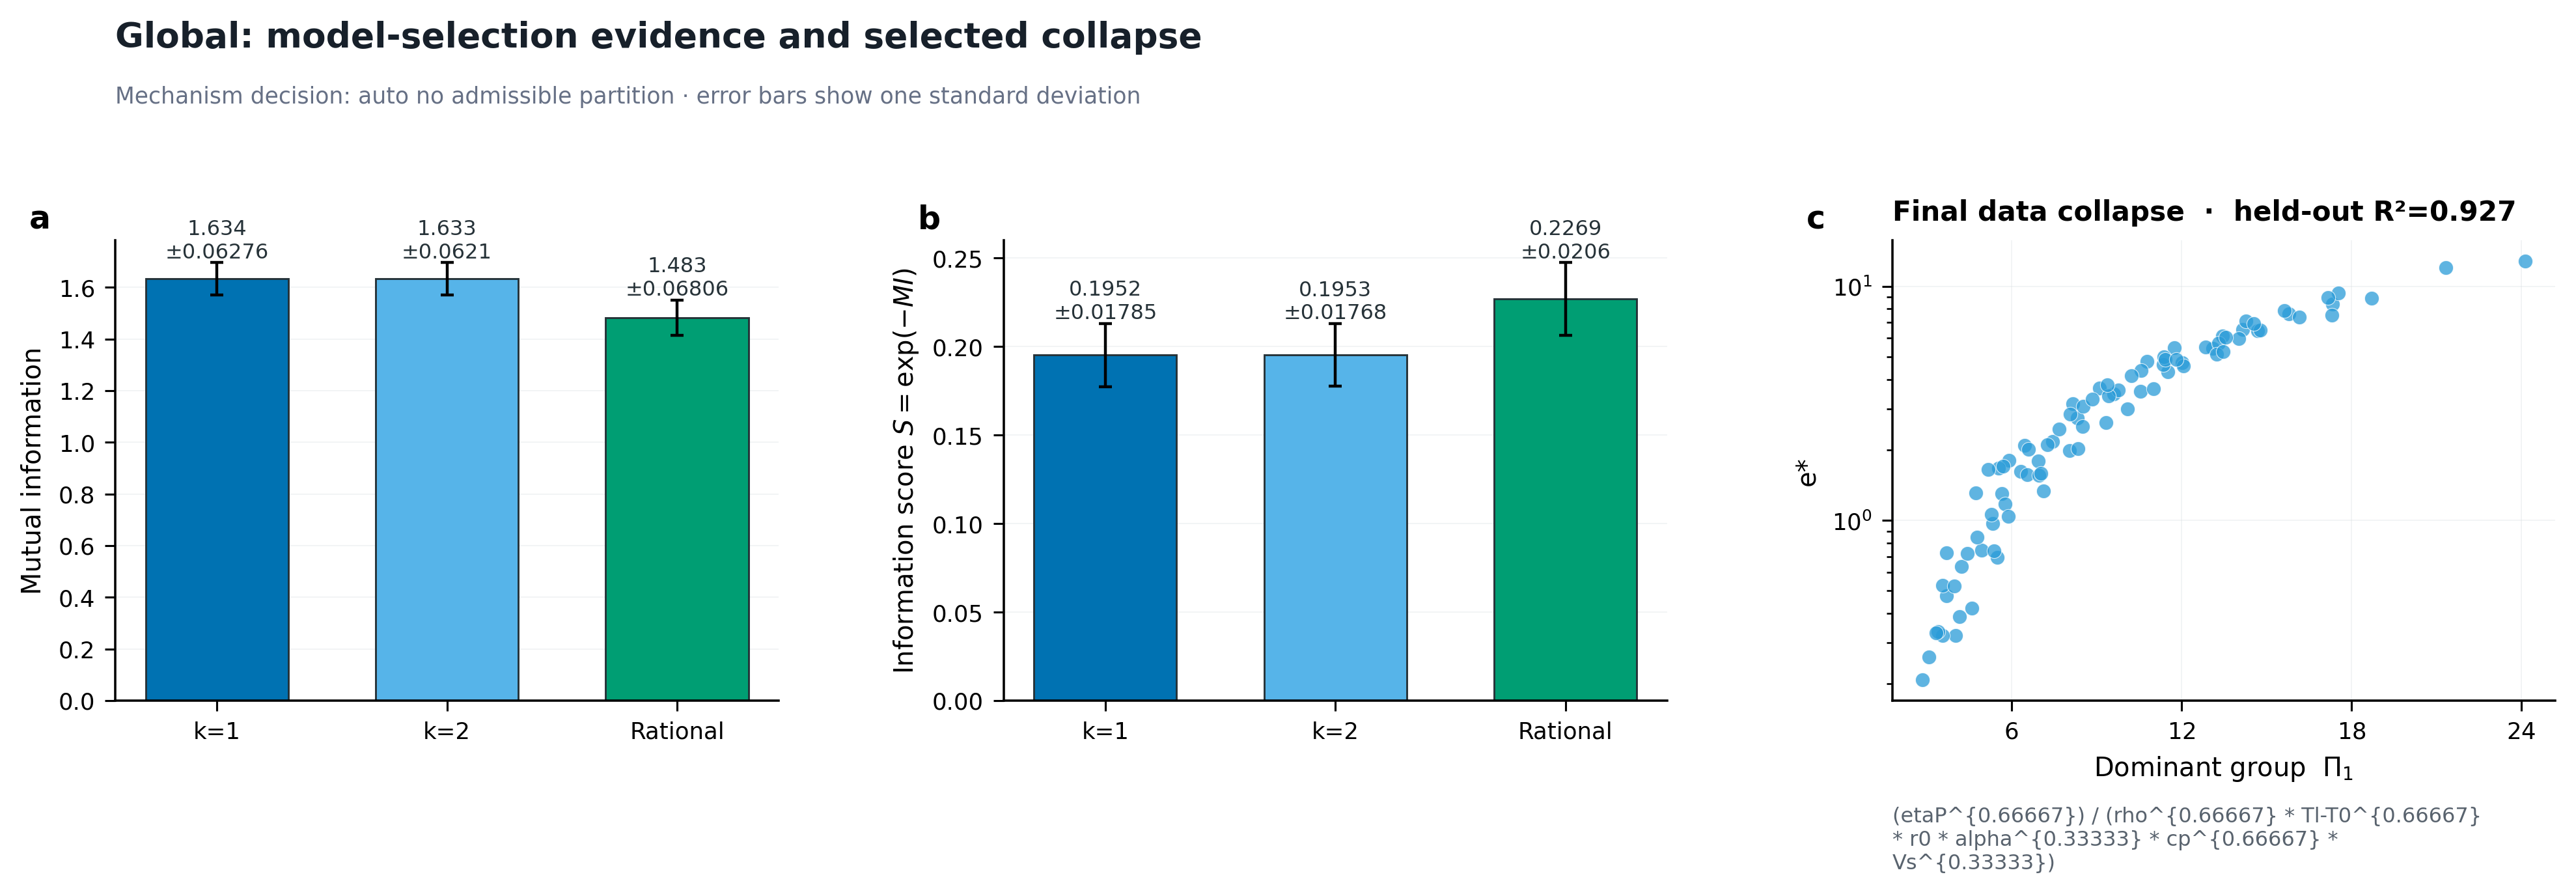